# 01 — Data Understanding and Exploratory Data Analysis (EDA)

**Project:** End-to-End House Price Prediction  
**Dataset:** Kaggle — House Prices: Advanced Regression Techniques (Ames, Iowa)

## Notebook objective
Understand the training dataset, identify data-quality issues, explore variables that relate to `SalePrice`, and generate visualizations before building a model.

> **Important:** `train.csv` contains the known target `SalePrice`. `test.csv` does not contain the target and is reserved for final predictions. Do not use `sample_submission.csv` as training data.

In [1]:
from pathlib import Path        #pathlib is a Python library used to work with file and folder paths.Path helps us create paths in a clean, operating-system-independent way.
import sys
import pandas as pd         #Used to work with csv, excel file, handle missing values, filter and analyze data
import numpy as np          # uses to perform mathematical operations
import matplotlib.pyplot as plt         # for graph and visualization
import seaborn as sns                   #It helps us create attractive statistical charts--Heatmaps, Box plots,Distribution plots
from IPython.display import display

PROJECT_ROOT = Path.cwd()                   #current working directory.
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data import load_training_data, prepare_features, iqr_outlier_summary      #Importing our own project functions
from src.eda import create_eda_charts

DATA_PATH = PROJECT_ROOT / "data" / "train.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "charts"

sns.set_theme(style="whitegrid")            #This sets the default Seaborn chart style.whitegrid gives charts a white background with grid lines, making values easier to read.
train = load_training_data(DATA_PATH)
print("Training shape:", train.shape)
print("Test file should be used only for prediction; it has no SalePrice column.")

Training shape: (1460, 81)
Test file should be used only for prediction; it has no SalePrice column.


## 1. Understand the dataset
Each row represents one sold property. `SalePrice` is the value we want the model to predict. `Id` is only a row identifier and is not a meaningful price predictor.

In [2]:
display(train.head())
print("Rows and columns:", train.shape)         #shape gives both rows and columns.len(train) gives only the number of rows.
print("\nData types:")
display(train.dtypes.value_counts().rename_axis("dtype").to_frame("column_count"))
print("\nNumeric summary:")
display(train.describe().T.head(20))            #This is one of the most useful Pandas commands for EDA.

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Rows and columns: (1460, 81)

Data types:


,column_count
dtype,
object,43
int64,35
float64,3



Numeric summary:


,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


## 2. Missing-value analysis
A blank value can mean that a feature does not exist (for example, no pool or no garage), not necessarily that the value is unknown. We use `data_description.txt` to interpret those fields.

In [3]:
missing = train.isna().sum().sort_values(ascending=False)   #Checks every cell in the DataFrame and identifies whether its value is missing.
missing = missing[missing > 0]                  
missing_df = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": (missing / len(train) * 100).round(2)
})
display(missing_df.head(25))

,missing_count,missing_percent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageQual,81,5.55
GarageFinish,81,5.55
GarageType,81,5.55


## 3. Target variable — SalePrice
A histogram helps us understand the distribution. House prices often have a right-skewed distribution, meaning a smaller number of expensive properties form a long tail.

In [4]:
%matplotlib inline

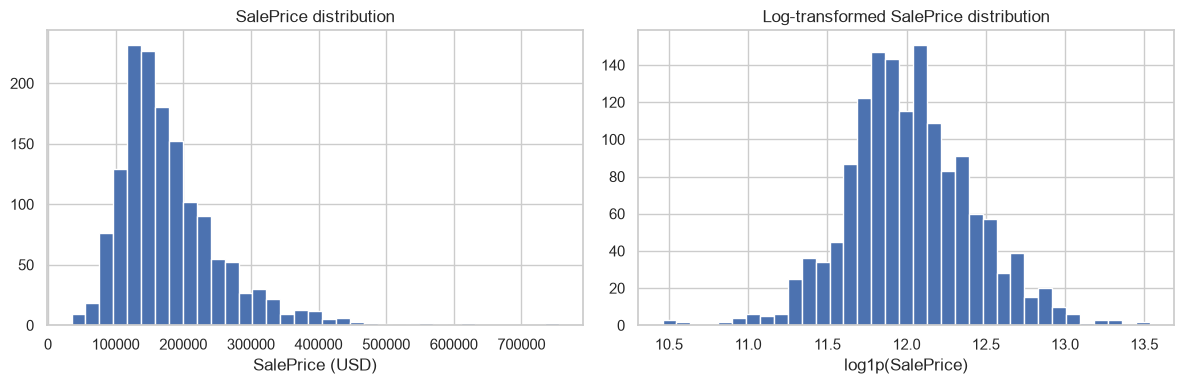

Mean: 180921.19589041095
Median: 163000.0
Skewness: 1.8828757597682129


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train["SalePrice"], bins=35)
axes[0].set_title("SalePrice distribution")
axes[0].set_xlabel("SalePrice (USD)")
axes[1].hist(np.log1p(train["SalePrice"]), bins=35)
axes[1].set_title("Log-transformed SalePrice distribution")
axes[1].set_xlabel("log1p(SalePrice)")
plt.tight_layout()
plt.show()

print("Mean:", train["SalePrice"].mean())
print("Median:", train["SalePrice"].median())
print("Skewness:", train["SalePrice"].skew())

## 4. Bivariate analysis
We inspect how living area and overall quality relate to sale price. These plots show associations, not proof that one variable causes a price change.

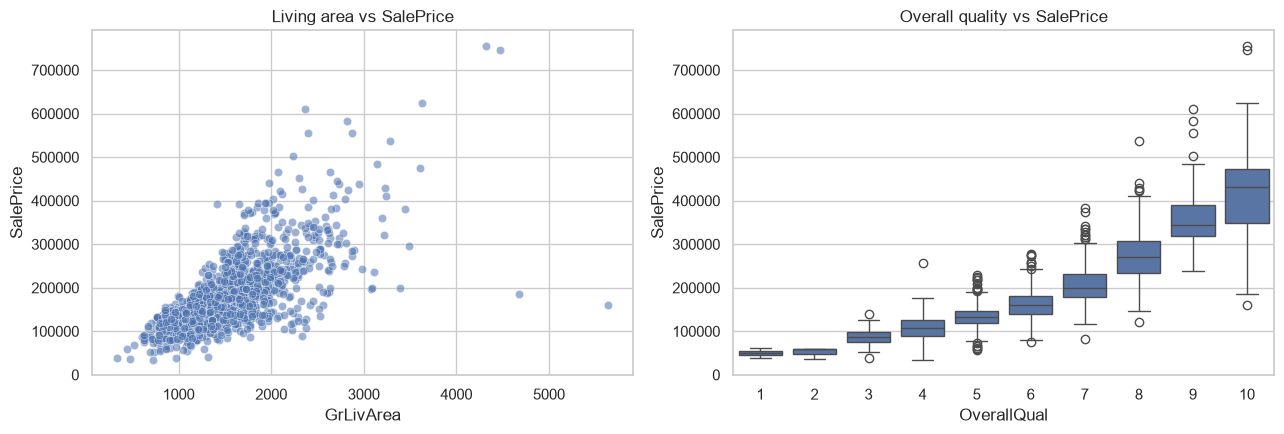

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))       #help us understand which house features influence the selling price
sns.scatterplot(data=train, x="GrLivArea", y="SalePrice", alpha=.55, ax=axes[0])
axes[0].set_title("Living area vs SalePrice")
sns.boxplot(data=train, x="OverallQual", y="SalePrice", ax=axes[1])
axes[1].set_title("Overall quality vs SalePrice")
plt.tight_layout()
plt.show()

## 5. Neighborhood aggregation
The group-by operation calculates the average and median sale price for each neighborhood. This is useful for understanding location-related differences in the historical Ames dataset.

,count,mean,median
Neighborhood,,,
NoRidge,41,335295.317073,301500.0
NridgHt,77,316270.623377,315000.0
StoneBr,25,310499.000000,278000.0
Timber,38,242247.447368,228475.0
Veenker,11,238772.727273,218000.0
Somerst,86,225379.837209,225500.0
ClearCr,28,212565.428571,200250.0
Crawfor,51,210624.725490,200624.0
CollgCr,150,197965.773333,197200.0


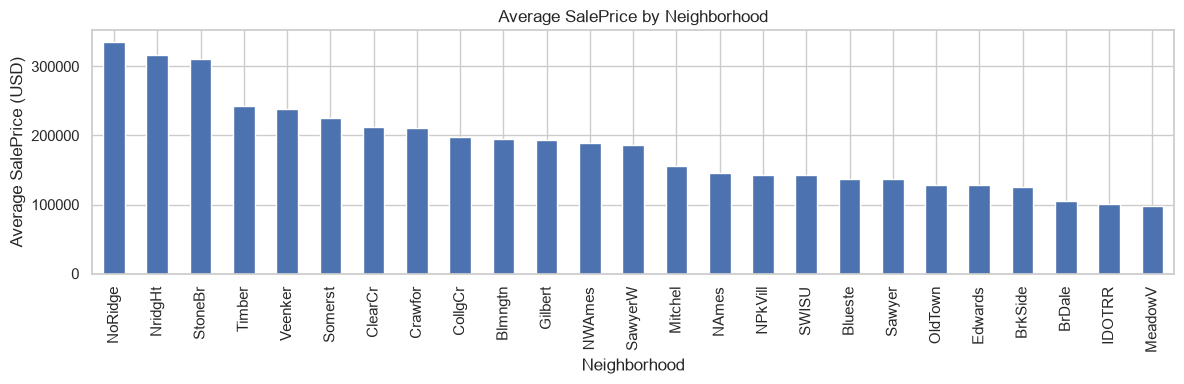

In [7]:
neighborhood_summary = (
    train.groupby("Neighborhood")["SalePrice"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)
display(neighborhood_summary)
neighborhood_summary["mean"].plot(kind="bar", figsize=(12, 4), title="Average SalePrice by Neighborhood")
plt.ylabel("Average SalePrice (USD)")
plt.tight_layout()
plt.show()

## 6. Correlation analysis
Correlation measures the strength and direction of a linear relationship. A high correlation does not prove causation. We use the target to identify numeric variables worth investigating.

,correlation_with_SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


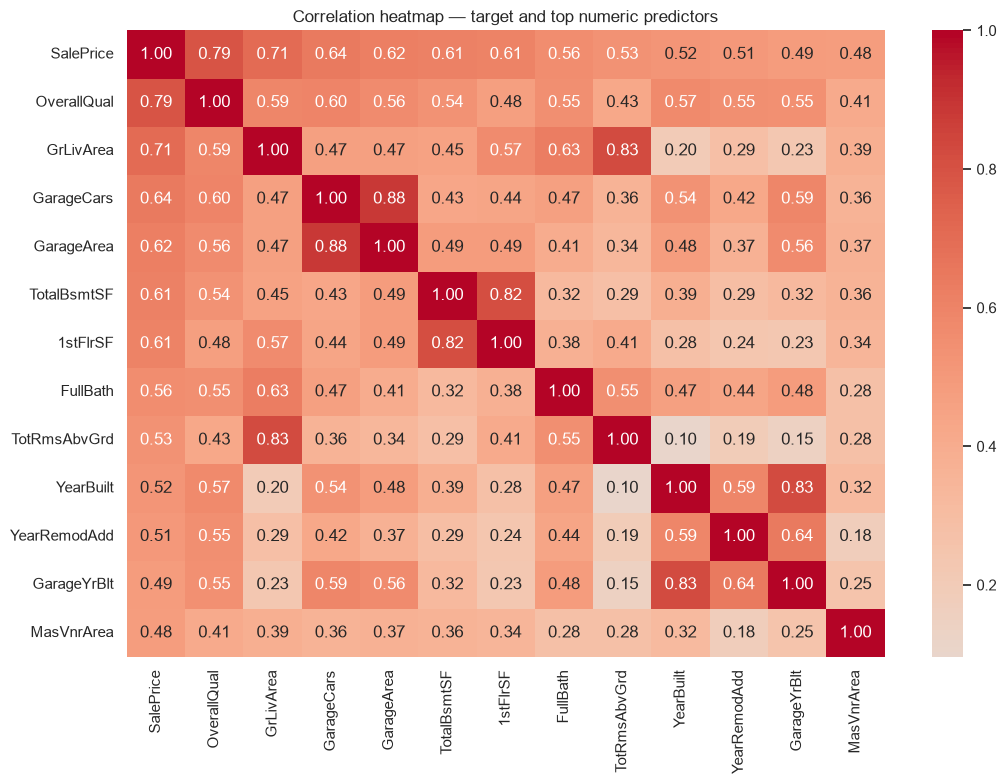

In [8]:
# we are identifying which numerical house features have the strongest relationship with SalePrice.
numeric = train.select_dtypes(include="number").drop(columns=["Id"], errors="ignore")
corr = numeric.corr(numeric_only=True)["SalePrice"].drop("SalePrice")
display(corr.reindex(corr.abs().sort_values(ascending=False).index).head(15).to_frame("correlation_with_SalePrice"))

top = ["SalePrice"] + corr.abs().sort_values(ascending=False).head(12).index.tolist()
plt.figure(figsize=(11, 8))
sns.heatmap(numeric[top].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlation heatmap — target and top numeric predictors")
plt.tight_layout()
plt.show()

## 7. Outlier detection using IQR
IQR = Q3 − Q1. Values below Q1 − 1.5×IQR or above Q3 + 1.5×IQR are flagged. We review them instead of automatically deleting them because an expensive or unusually large house may be a valid property.
Your code checks whether some house prices, living areas, and plot areas are unusually high or low compared with the rest of the dataset.

In [9]:
for col in ["SalePrice", "GrLivArea", "LotArea"]:
    print(col, iqr_outlier_summary(train[col]))

SalePrice {'q1': 129975.0, 'q3': 214000.0, 'iqr': 84025.0, 'lower_bound': 3937.5, 'upper_bound': 340037.5, 'flagged_rows': 61}
GrLivArea {'q1': 1129.5, 'q3': 1776.75, 'iqr': 647.25, 'lower_bound': 158.625, 'upper_bound': 2747.625, 'flagged_rows': 31}
LotArea {'q1': 7553.5, 'q3': 11601.5, 'iqr': 4048.0, 'lower_bound': 1481.5, 'upper_bound': 17673.5, 'flagged_rows': 69}


## 8. Derived fields for analysis
We create `HouseAge` and `TotalArea` from property details. We also calculate `PricePerSqFt` for descriptive analysis only. **Do not use `PricePerSqFt` as a model input**, because it is calculated using the target `SalePrice` and would leak the answer into training.

In [10]:
eda_view = train.copy()
eda_view["HouseAge"] = (eda_view["YrSold"] - eda_view["YearBuilt"]).clip(lower=0)
eda_view["TotalArea"] = eda_view["GrLivArea"] + eda_view["TotalBsmtSF"].fillna(0)
eda_view["PricePerSqFt"] = eda_view["SalePrice"] / eda_view["GrLivArea"].replace(0, np.nan)
display(eda_view[["Id", "SalePrice", "GrLivArea", "HouseAge", "TotalArea", "PricePerSqFt"]].head())
print("PricePerSqFt is for EDA only; it is excluded from X.")

,Id,SalePrice,GrLivArea,HouseAge,TotalArea,PricePerSqFt
0,1,208500,1710,5,2566,121.929825
1,2,181500,1262,31,2524,143.819334
2,3,223500,1786,7,2706,125.139978
3,4,140000,1717,91,2473,81.537566
4,5,250000,2198,8,3343,113.739763


PricePerSqFt is for EDA only; it is excluded from X.


## 9. Create reusable EDA charts and engineered features
`prepare_features()` creates fields such as `HouseAge`, `RemodAge`, `GarageAge`, `TotalArea`, and `TotalBathrooms`. `SalePrice` is deliberately not used to create any model input feature.

Feature engineering means creating new useful columns from existing dataset columns to help us understand the data and potentially improve model performance.

In [11]:
X = prepare_features(train)
print("Original training shape:", train.shape)
print("Feature matrix shape after feature engineering:", X.shape)
display(X.head())

eda_results = create_eda_charts(train, OUTPUT_DIR)
print("Charts saved:")
display(eda_results["charts"])

Original training shape: (1460, 81)
Feature matrix shape after feature engineering: (1460, 89)


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,HouseAge,RemodAge,GarageAge,TotalArea,TotalBathrooms,TotalPorchSF,HasGarage,HasBasement,HasFireplace,HasPool
0,60,RL,65.0,8450,Pave,None,Reg,Lvl,AllPub,Inside,...,5,5,5.0,2566,3.5,61,1,1,0,0
1,20,RL,80.0,9600,Pave,None,Reg,Lvl,AllPub,FR2,...,31,31,31.0,2524,2.5,298,1,1,1,0
2,60,RL,68.0,11250,Pave,None,IR1,Lvl,AllPub,Inside,...,7,6,7.0,2706,3.5,42,1,1,1,0
3,70,RL,60.0,9550,Pave,None,IR1,Lvl,AllPub,Corner,...,91,36,8.0,2473,2.0,307,1,1,1,0
4,60,RL,84.0,14260,Pave,None,IR1,Lvl,AllPub,FR2,...,8,8,8.0,3343,3.5,276,1,1,1,0


Charts saved:


{'saleprice_distribution': 'c:\\Users\\ACER\\OneDrive\\Desktop\\BIG DATA ANALYTICS\\Projects\\House_Price_Prediction_Kaggle_RealData\\outputs\\charts\\01_saleprice_distribution.png',
 'area_quality': 'c:\\Users\\ACER\\OneDrive\\Desktop\\BIG DATA ANALYTICS\\Projects\\House_Price_Prediction_Kaggle_RealData\\outputs\\charts\\02_area_quality_relationships.png',
 'neighborhood': 'c:\\Users\\ACER\\OneDrive\\Desktop\\BIG DATA ANALYTICS\\Projects\\House_Price_Prediction_Kaggle_RealData\\outputs\\charts\\03_neighborhood_average_price.png',
 'missing_values': 'c:\\Users\\ACER\\OneDrive\\Desktop\\BIG DATA ANALYTICS\\Projects\\House_Price_Prediction_Kaggle_RealData\\outputs\\charts\\04_missing_values.png',
 'correlation': 'c:\\Users\\ACER\\OneDrive\\Desktop\\BIG DATA ANALYTICS\\Projects\\House_Price_Prediction_Kaggle_RealData\\outputs\\charts\\05_correlation_heatmap.png',
 'house_age_price_per_sqft': 'c:\\Users\\ACER\\OneDrive\\Desktop\\BIG DATA ANALYTICS\\Projects\\House_Price_Prediction_Kaggle_R

## EDA conclusion — write your observations
After running the notebook on the supplied data, write 4–6 observations such as:
- Which numeric feature has the strongest correlation with `SalePrice`?
- How does average price differ by neighborhood?
- Does the price generally increase with living area?
- How does overall quality relate to price?
- Which columns have the most missing values, and which missing values mean “feature absent”?
- Which outliers should be reviewed rather than automatically removed?

Use the actual outputs from your run; do not invent results.